# Randomised Control Trials

## Analysing Beat-the-Blues Dataset with RCT

### Installing necessary packages

In [9]:
install.packages(c("HSAUR3", "lme4", "lmerTest", "broom.mixed", "gtsummary", "tidyverse", "knitr"))
library(HSAUR3); library(tidyverse); library(lme4); library(lmerTest)
library(broom.mixed); library(gtsummary); library(knitr)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: Matrix


Attaching package: ‘Matrix’


The following objects are masked from ‘package:tidyr’:

    expand, pack, unpack



Attaching package: ‘lme4’


The following object is masked from ‘package:HSAUR3’:

    schizophrenia



Attaching package: ‘lmerTest’


The following object is masked from ‘package:lme4’:

    lmer


The following object is masked from ‘packag

### Loading and preparing data

In [10]:
data("BtheB", package = "HSAUR3")
bt <- BtheB %>% mutate(subject = factor(row_number()))
visits <- c("bdi.2m", "bdi.3m", "bdi.5m", "bdi.8m")
str(bt)

'data.frame':	100 obs. of  9 variables:
 $ drug     : Factor w/ 2 levels "No","Yes": 1 2 2 1 2 2 2 1 2 2 ...
 $ length   : Factor w/ 2 levels "<6m",">6m": 2 2 1 2 2 1 1 2 1 2 ...
 $ treatment: Factor w/ 2 levels "TAU","BtheB": 1 2 1 2 2 2 1 1 2 2 ...
 $ bdi.pre  : num  29 32 25 21 26 7 17 20 18 20 ...
 $ bdi.2m   : num  2 16 20 17 23 0 7 20 13 5 ...
 $ bdi.3m   : num  2 24 NA 16 NA 0 7 21 14 5 ...
 $ bdi.5m   : num  NA 17 NA 10 NA 0 3 19 20 8 ...
 $ bdi.8m   : num  NA 20 NA 9 NA 0 7 13 11 12 ...
 $ subject  : Factor w/ 100 levels "1","2","3","4",..: 1 2 3 4 5 6 7 8 9 10 ...


In [11]:
flow <- bt %>%
  group_by(treatment) %>%
  summarise(randomised = n(),
            across(all_of(visits), ~ sum(!is.na(.x)), .names = "observed_{.col}"))
kable(flow)



|treatment | randomised| observed_bdi.2m| observed_bdi.3m| observed_bdi.5m| observed_bdi.8m|
|:---------|----------:|---------------:|---------------:|---------------:|---------------:|
|TAU       |         48|              45|              36|              29|              25|
|BtheB     |         52|              52|              37|              29|              27|

In [12]:
bt %>%
  select(treatment, bdi.pre, drug, length) %>%
  tbl_summary(by = treatment,
              statistic = list(all_continuous() ~ "{mean} ({sd})"),
              label = list(bdi.pre ~ "Baseline BDI", drug ~ "Antidepressant use",
                           length ~ "Episode length")) %>%
  add_overall() %>%
  as_kable()



|**Characteristic** | **Overall**  N = 100 | **TAU**  N = 48 | **BtheB**  N = 52 |
|:------------------|:--------------------:|:---------------:|:-----------------:|
|Baseline BDI       |       23 (11)        |     24 (10)     |      23 (12)      |
|Antidepressant use |       44 (44%)       |    14 (29%)     |     30 (58%)      |
|Episode length     |                      |                 |                   |
|<6m                |       49 (49%)       |    23 (48%)     |     26 (50%)      |
|>6m                |       51 (51%)       |    25 (52%)     |     26 (50%)      |

In [13]:
long <- bt %>%
  pivot_longer(all_of(visits), names_to = "visit", values_to = "bdi") %>%
  mutate(time = as.numeric(str_extract(visit, "\\d+")))

In [14]:
m1 <- lmer(bdi ~ bdi.pre + time + treatment + drug + length + (1 | subject),
           data = long, REML = FALSE, na.action = na.omit)
summary(m1)
tidy(m1, effects = "fixed", conf.int = TRUE) %>% kable(digits = 2)

# Intraclass correlation: share of variance between patients
vc <- as.data.frame(VarCorr(m1))
icc <- vc$vcov[1] / sum(vc$vcov); round(icc, 2)

Linear mixed model fit by maximum likelihood . t-tests use Satterthwaite's
  method [lmerModLmerTest]
Formula: bdi ~ bdi.pre + time + treatment + drug + length + (1 | subject)
   Data: long

      AIC       BIC    logLik -2*log(L)  df.resid 
   1887.5    1916.6    -935.7    1871.5       272 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-2.6975 -0.5026 -0.0638  0.4124  3.8203 

Random effects:
 Groups   Name        Variance Std.Dev.
 subject  (Intercept) 48.78    6.984   
 Residual             25.14    5.014   
Number of obs: 280, groups:  subject, 97

Fixed effects:
                Estimate Std. Error        df t value Pr(>|t|)    
(Intercept)      5.59239    2.24244 108.97862   2.494   0.0141 *  
bdi.pre          0.63968    0.07789 104.08341   8.212 6.28e-13 ***
time            -0.70476    0.14639 199.31615  -4.814 2.92e-06 ***
treatmentBtheB  -2.32908    1.67036  97.12303  -1.394   0.1664    
drugYes         -2.82495    1.72684  98.19501  -1.636   0.1051    
length>6m



|effect |term           | estimate| std.error| statistic|     df| p.value| conf.low| conf.high|
|:------|:--------------|--------:|---------:|---------:|------:|-------:|--------:|---------:|
|fixed  |(Intercept)    |     5.59|      2.24|      2.49| 108.98|    0.01|     1.15|     10.04|
|fixed  |bdi.pre        |     0.64|      0.08|      8.21| 104.08|    0.00|     0.49|      0.79|
|fixed  |time           |    -0.70|      0.15|     -4.81| 199.32|    0.00|    -0.99|     -0.42|
|fixed  |treatmentBtheB |    -2.33|      1.67|     -1.39|  97.12|    0.17|    -5.64|      0.99|
|fixed  |drugYes        |    -2.82|      1.73|     -1.64|  98.20|    0.11|    -6.25|      0.60|
|fixed  |length>6m      |     0.20|      1.64|      0.12| 100.26|    0.90|    -3.05|      3.45|

[1] 0.66

In [15]:
m2 <- lmer(bdi ~ bdi.pre + time + treatment + drug + length + (time | subject),
           data = long, REML = FALSE, na.action = na.omit)
anova(m1, m2)

,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
m1,8,1887.492,1916.570,-935.7460,1871.492,NA,NA,NA
m2,10,1891.038,1927.386,-935.5189,1871.038,0.4541645,2,0.7968552


In [16]:
m3 <- lmer(bdi ~ bdi.pre + time * treatment + drug + length + (1 | subject),
           data = long, REML = FALSE, na.action = na.omit)
anova(m1, m3)
tidy(m3, effects = "fixed", conf.int = TRUE) %>% kable(digits = 2)

,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
m1,8,1887.492,1916.570,-935.7460,1871.492,NA,NA,NA
m3,9,1886.690,1919.404,-934.3452,1868.690,2.801534,1,0.09417417




|effect |term                | estimate| std.error| statistic|     df| p.value| conf.low| conf.high|
|:------|:-------------------|--------:|---------:|---------:|------:|-------:|--------:|---------:|
|fixed  |(Intercept)         |     6.48|      2.32|      2.79| 119.83|    0.01|     1.89|     11.07|
|fixed  |bdi.pre             |     0.64|      0.08|      8.17| 103.19|    0.00|     0.48|      0.80|
|fixed  |time                |    -0.96|      0.21|     -4.59| 196.76|    0.00|    -1.37|     -0.54|
|fixed  |treatmentBtheB      |    -4.10|      1.98|     -2.06| 174.39|    0.04|    -8.02|     -0.18|
|fixed  |drugYes             |    -2.79|      1.74|     -1.60|  97.53|    0.11|    -6.25|      0.66|
|fixed  |length>6m           |     0.22|      1.65|      0.13|  99.53|    0.89|    -3.06|      3.49|
|fixed  |time:treatmentBtheB |     0.49|      0.29|      1.69| 198.48|    0.09|    -0.08|      1.06|

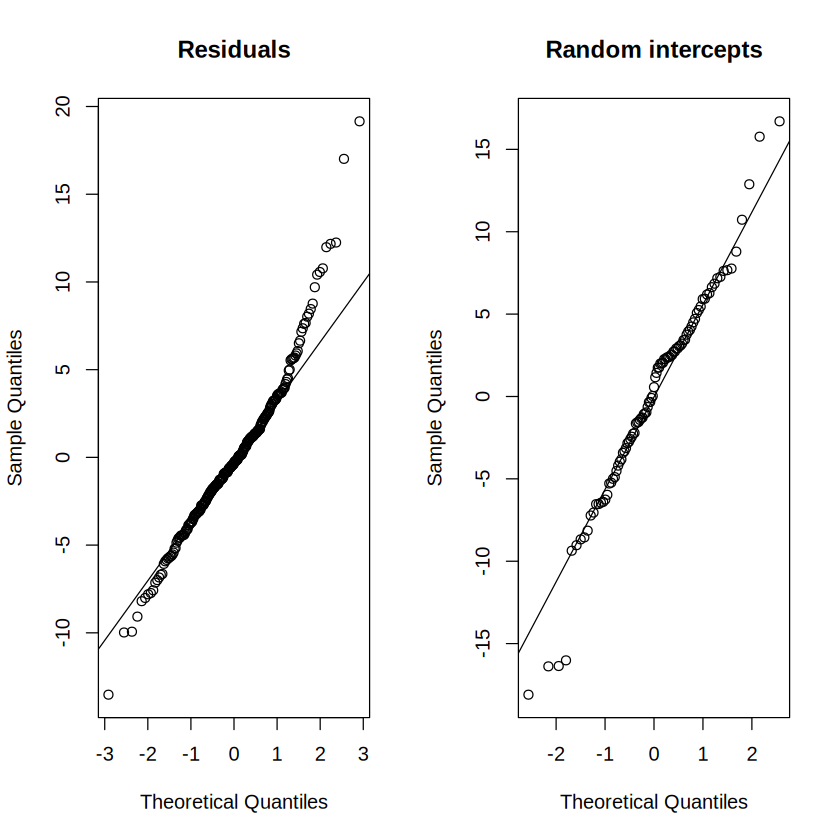

In [17]:
par(mfrow = c(1, 2))
qqnorm(resid(m1), main = "Residuals"); qqline(resid(m1))
re <- ranef(m1)$subject[, 1]
qqnorm(re, main = "Random intercepts"); qqline(re)

In [18]:
# Does dropout relate to arm or baseline severity?
bt <- bt %>% mutate(dropped = if_any(all_of(visits), is.na))
glm(dropped ~ treatment + bdi.pre, family = binomial, data = bt) %>%
  tidy(exponentiate = TRUE, conf.int = TRUE) %>% kable(digits = 2)

# Complete-case analysis: patients observed at every visit
complete_ids <- bt %>% filter(!dropped) %>% pull(subject)
m_cc <- lmer(bdi ~ bdi.pre + time + treatment + drug + length + (1 | subject),
             data = filter(long, subject %in% complete_ids), REML = FALSE)

bind_rows(
  tidy(m1,   effects = "fixed", conf.int = TRUE) %>% mutate(analysis = "Mixed model, all data (MAR)"),
  tidy(m_cc, effects = "fixed", conf.int = TRUE) %>% mutate(analysis = "Complete case (MCAR)")
) %>%
  filter(term == "treatmentBtheB") %>%
  select(analysis, estimate, conf.low, conf.high, p.value) %>%
  kable(digits = 2)



|term           | estimate| std.error| statistic| p.value| conf.low| conf.high|
|:--------------|--------:|---------:|---------:|-------:|--------:|---------:|
|(Intercept)    |     0.80|      0.54|     -0.41|    0.68|     0.28|      2.30|
|treatmentBtheB |     1.02|      0.40|      0.04|    0.97|     0.46|      2.24|
|bdi.pre        |     1.01|      0.02|      0.30|    0.76|     0.97|      1.04|



|analysis                    | estimate| conf.low| conf.high| p.value|
|:---------------------------|--------:|--------:|---------:|-------:|
|Mixed model, all data (MAR) |    -2.33|    -5.64|      0.99|    0.17|
|Complete case (MCAR)        |    -4.42|    -8.51|     -0.34|    0.03|

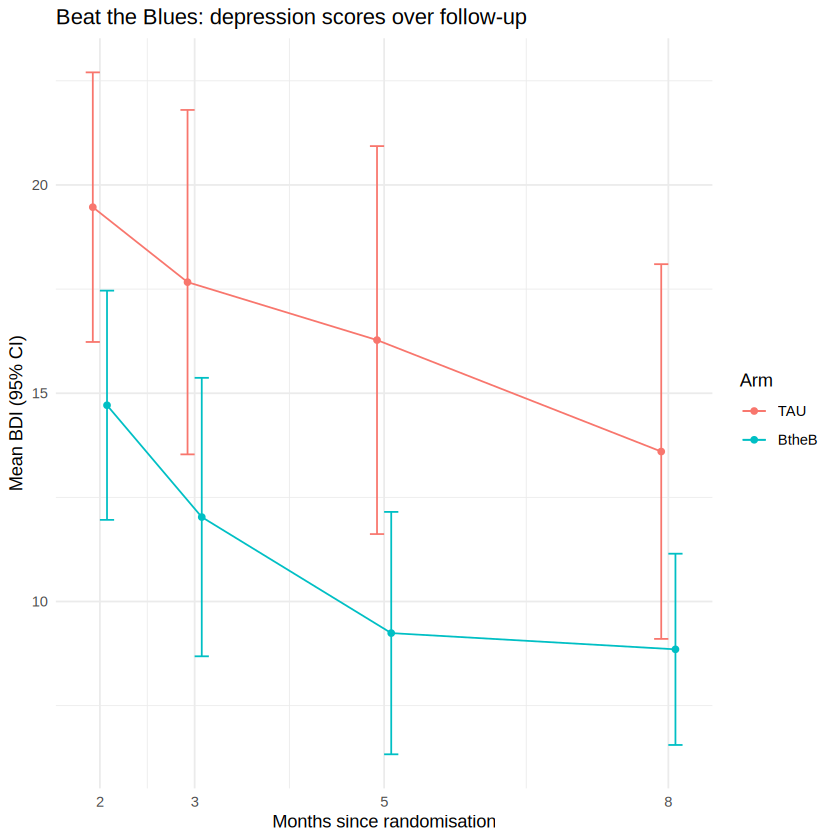

In [19]:
summ <- long %>%
  filter(!is.na(bdi)) %>%
  group_by(treatment, time) %>%
  summarise(n = n(), mean = mean(bdi), se = sd(bdi) / sqrt(n), .groups = "drop")

p <- ggplot(summ, aes(time, mean, colour = treatment)) +
  geom_line(position = position_dodge(0.3)) +
  geom_point(position = position_dodge(0.3)) +
  geom_errorbar(aes(ymin = mean - 1.96 * se, ymax = mean + 1.96 * se),
                width = 0.3, position = position_dodge(0.3)) +
  scale_x_continuous(breaks = c(2, 3, 5, 8)) +
  labs(x = "Months since randomisation", y = "Mean BDI (95% CI)", colour = "Arm",
       title = "Beat the Blues: depression scores over follow-up") +
  theme_minimal()
p
ggsave("bdi_over_time.png", p, width = 7, height = 4.5, dpi = 200)